# EDA — Dataset de planograma para negocios pequeños
**Tecnológico de Monterrey  MNA  TC5035 Proyecto Integrador  Equipo 48**
 fase 1: *Entendimiento del negocio y de los datos*.

> **Aviso de transparencia.** Este entorno no tiene acceso a internet, por lo que **no fue posible descargar un dataset público real** ni se puede tocar el repositorio de Bnext (que además está bajo NDA y solo es accesible por VPN). Para poder ejecutar y mostrar todo el pipeline de EDA se genera un **dataset sintético de anaqueles de tienda pequeña** con anotaciones, planograma de referencia y degradaciones realistas de captura (iluminación, desenfoque, ruido, perspectiva, oclusión, duplicados).
> Las **cifras de este notebook son ilustrativas del método, no hallazgos sobre datos reales**

In [1]:
import os, json, math, random, warnings, hashlib
import numpy as np, pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

SEED = 48
rng = np.random.default_rng(SEED); random.seed(SEED)
USE_SYNTHETIC = True
DATA_DIR = os.path.expanduser(os.environ.get('AVANCE1_DATA_DIR', '~/week3/data'))
IMG_DIR = os.path.join(DATA_DIR, 'images')
os.makedirs(IMG_DIR, exist_ok=True)
print('OpenCV', cv2.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
print('Modo:', 'SINTÉTICO (stand-in)' if USE_SYNTHETIC else 'DATOS REALES')

OpenCV 5.0.0 | numpy 2.5.4 | pandas 3.0.6
Modo: SINTÉTICO (stand-in)


## 1. Generación del dataset sintético (stand-in)
Se simulan **8 tiendas**, cada una con **2 muebles** con su planograma (categoría esperada por posición). Cada captura puede tener posiciones *correctas*, *faltantes* (hueco) o *mal ubicadas* (producto de otra categoría). Después se aplican condiciones de captura distintas según el **dispositivo** (resolución y calidad).

In [2]:
CATS = ['bebidas','botanas','lacteos','galletas','limpieza','enlatados']
BASE_RGB = {'bebidas':(200,40,40),'botanas':(235,170,30),'lacteos':(60,120,210),
            'galletas':(150,90,50),'limpieza':(40,170,120),'enlatados':(130,130,140)}
PROD_H = {'bebidas':0.80,'botanas':0.70,'lacteos':0.65,'galletas':0.50,'limpieza':0.85,'enlatados':0.40}
DEVICES = {'alto':(1600,1200),'medio':(1280,960),'basico':(800,600),'tablet_wide':(1280,720)}
DEV_BLUR = {'alto':(0.0,0.8),'medio':(0.0,1.5),'basico':(0.5,3.0),'tablet_wide':(0.0,2.0)}
DEV_NOISE = {'alto':(0,3),'medio':(0,5),'basico':(2,10),'tablet_wide':(1,7)}
W0, H0 = 1000, 750
N_STORES, N_MUEBLES = 8, 2

def make_layouts():
    L = {}
    for s in range(N_STORES):
        for m in range(N_MUEBLES):
            ns = int(rng.integers(3,5)); nl = int(rng.integers(8,13))
            shelves = []
            for _ in range(ns):
                seq, row = [], []
                while len(row) < nl:
                    c = CATS[int(rng.integers(0,len(CATS)))]
                    row += [c]*int(rng.integers(2,5))
                shelves.append(row[:nl])
            L[(s,m)] = shelves
    return L
LAYOUTS = make_layouts()

def make_scene(key, r):
    shelves = LAYOUTS[key]; slots = []
    p_missing = r.uniform(0.08, 0.30)           # cada visita tiene un nivel de faltantes distinto
    for i,row in enumerate(shelves):
        for j,e in enumerate(row):
            u = r.random()
            if u < p_missing: a, st = None, 'faltante'
            elif u < p_missing + 0.10:
                a = [c for c in CATS if c != e][int(r.integers(0,len(CATS)-1))]; st = 'mal_ubicado'
            else: a, st = e, 'correcto'
            slots.append(dict(shelf=i, slot=j, expected=e, actual=a, state=st,
                              jit=[float(r.uniform(.78,.92)), float(r.uniform(.92,1.0)), float(r.uniform(-18,18))]))
    return dict(key=key, shelves=shelves, slots=slots)

def render_scene(sc, r):
    img = np.full((H0,W0,3), (205,200,190), np.uint8)
    ns = len(sc['shelves']); nl = len(sc['shelves'][0])
    shelf_h = (H0-80)/ns; slot_w = (W0-60)/nl; plank = 14
    boxes = []
    for i in range(ns):
        top = 40 + i*shelf_h; bottom = top + shelf_h - plank
        cv2.rectangle(img,(20,int(top)),(W0-20,int(bottom)),(150,145,140),-1)      # panel trasero
        cv2.rectangle(img,(20,int(bottom)),(W0-20,int(bottom+plank)),(70,60,55),-1)  # charola
    for s in sc['slots']:
        i,j = s['shelf'], s['slot']
        top = 40 + i*shelf_h; bottom = top + shelf_h - plank
        x0 = 30 + j*slot_w
        if s['actual'] is None:
            x1 = x0+slot_w-2; y1 = bottom; y0 = bottom - 0.6*shelf_h
            if r.random()<0.5: cv2.rectangle(img,(int(x0+6),int(bottom-3)),(int(x0+slot_w*0.6),int(bottom+10)),(240,240,240),-1)
            boxes.append(('vacio', x0+1, y0, x1, y1, s)); continue
        c = s['actual']; wj,hj,cj = s['jit']
        w = slot_w*wj; h = PROD_H[c]*shelf_h*0.95*hj
        px0 = x0 + (slot_w-w)/2; px1 = px0 + w; py1 = bottom; py0 = bottom - h
        col = tuple(int(np.clip(v+cj,0,255)) for v in BASE_RGB[c])
        cv2.rectangle(img,(int(px0),int(py0)),(int(px1),int(py1)),col,-1)
        cv2.rectangle(img,(int(px0),int(py0+0.35*h)),(int(px1),int(py0+0.62*h)),(235,235,235),-1)
        cv2.rectangle(img,(int(px0),int(py0)),(int(px1),int(py0+0.1*h)),tuple(int(v*0.6) for v in col),-1)
        cv2.rectangle(img,(int(px0),int(py0)),(int(px1),int(py1)),(30,30,30),1)
        boxes.append((c, px0, py0, px1, py1, s))
    occ = None
    if r.random() < 0.12:
        cx,cy = int(r.uniform(.2,.8)*W0), int(r.uniform(.3,.8)*H0)
        ax,ay = int(r.uniform(.07,.13)*W0), int(r.uniform(.12,.22)*H0)
        cv2.ellipse(img,(cx,cy),(ax,ay),0,0,360,(120,140,170),-1); occ = (cx-ax,cy-ay,cx+ax,cy+ay)
    return img, boxes, occ

def capture(img, boxes, occ, device, r):
    # perspectiva leve
    j = r.uniform(0.0, 0.045)
    src = np.float32([[0,0],[W0,0],[W0,H0],[0,H0]])
    dst = src + r.uniform(-j,j,(4,2)).astype(np.float32)*np.float32([W0,H0])
    Hm = cv2.getPerspectiveTransform(src,dst)
    out = cv2.warpPerspective(img,Hm,(W0,H0),borderMode=cv2.BORDER_REPLICATE)
    # iluminación
    gain = r.choice([r.uniform(.45,.7), r.uniform(.8,1.15), r.uniform(1.15,1.45)], p=[.15,.7,.15])
    out = np.clip(out.astype(np.float32)*gain, 0, 255)
    cast = r.uniform(.9,1.1,3); out = np.clip(out*cast,0,255)
    # desenfoque
    lo,hi = DEV_BLUR[device]; sig = r.uniform(lo,hi)
    if sig>0.3: out = cv2.GaussianBlur(out,(0,0),sig)
    # ruido
    nlo,nhi = DEV_NOISE[device]; ns = r.uniform(nlo,nhi)
    if ns>0: out = out + r.normal(0,ns,out.shape)
    out = np.clip(out,0,255).astype(np.uint8)
    dw,dh = DEVICES[device]; out = cv2.resize(out,(dw,dh),interpolation=cv2.INTER_AREA)
    recs = []
    for (c,x0,y0,x1,y1,s) in boxes:
        pts = cv2.perspectiveTransform(np.float32([[[x0,y0],[x1,y0],[x1,y1],[x0,y1]]]),Hm)[0]
        bx0,by0 = pts.min(0); bx1,by1 = pts.max(0)
        bx0,bx1 = np.clip([bx0,bx1],0,W0); by0,by1 = np.clip([by0,by1],0,H0)
        ov = 0.0
        if occ is not None:
            ix = max(0,min(bx1,occ[2])-max(bx0,occ[0])); iy = max(0,min(by1,occ[3])-max(by0,occ[1]))
            ov = ix*iy/max((bx1-bx0)*(by1-by0),1)
        recs.append(dict(cls=c, xmin=bx0/W0, ymin=by0/H0, xmax=bx1/W0, ymax=by1/H0, occ=round(ov,3),
                         shelf=s['shelf'], slot=s['slot'], expected=s['expected'], state=s['state']))
    return out, recs, dict(gain=gain, blur_sigma=sig, noise_sigma=ns, persp=j)

def generate(n_scenes=330, n_dups=30):
    imgs, boxes_all, scenes_cache = [], [], []
    k = 0
    for n in range(n_scenes + n_dups):
        is_dup = n >= n_scenes
        if is_dup:
            sc, sc_id, prev_store = scenes_cache[int(rng.integers(0, n_scenes))]
        else:
            key = (int(rng.integers(0,N_STORES)), int(rng.integers(0,N_MUEBLES)))
            sc = make_scene(key, rng); sc_id = n; prev_store = key
            scenes_cache.append((sc, sc_id, key))
        img, boxes, occ = render_scene(sc, rng)
        dev = list(DEVICES)[int(rng.choice(4, p=[.25,.35,.3,.1]))]
        out, recs, meta = capture(img, boxes, occ, dev, rng)
        fn = f'img_{k:04d}.jpg'
        Image.fromarray(out[:,:,::-1]).save(os.path.join(IMG_DIR,fn), quality=int(rng.integers(70,96)))
        day = int(rng.integers(0,60))
        imgs.append(dict(image=fn, scene_id=sc_id, store=f'T{prev_store[0]+1:02d}', mueble=prev_store[1],
                         device=dev, date=str(pd.Timestamp('2026-07-01')+pd.Timedelta(days=day)).split()[0],
                         has_occluder=occ is not None, is_planted_dup=is_dup, **meta))
        for b in recs: boxes_all.append(dict(image=fn, **b))
        k += 1
    return pd.DataFrame(imgs), pd.DataFrame(boxes_all)

if USE_SYNTHETIC:
    images_meta, boxes = generate()
    images_meta.to_csv(os.path.join(DATA_DIR,'images_meta.csv'), index=False)
    boxes.to_csv(os.path.join(DATA_DIR,'annotations.csv'), index=False)
print(f'Imágenes generadas: {len(images_meta)} | anotaciones: {len(boxes)}')
print('Tamaño en disco: %.1f MB' % (sum(os.path.getsize(os.path.join(IMG_DIR,f)) for f in os.listdir(IMG_DIR))/1e6))

Imágenes generadas: 360 | anotaciones: 12570
Tamaño en disco: 39.5 MB


## 2. Vista general del dataset
Primero el esquema de las tablas (imágenes y anotaciones) y una muestra de imágenes con sus cajas delimitadoras.

In [3]:
print('--- images_meta (primeras filas) ---')
print(images_meta[['image','store','mueble','device','date','has_occluder']].head(6).to_string(index=False))
print('\n--- annotations (primeras filas) ---')
print(boxes[['image','cls','xmin','ymin','xmax','ymax','state']].head(6).round(3).to_string(index=False))
print('\nTiendas:', images_meta.store.nunique(), '| Dispositivos:', images_meta.device.nunique(),
      '| Rango de fechas:', images_meta.date.min(), '→', images_meta.date.max())
print('Valores nulos en anotaciones:', int(boxes.isna().sum().sum()))

--- images_meta (primeras filas) ---
       image store  mueble device       date  has_occluder
img_0000.jpg   T08       1 basico 2026-07-15         False
img_0001.jpg   T05       1   alto 2026-08-22         False
img_0002.jpg   T06       1  medio 2026-08-17         False
img_0003.jpg   T05       1 basico 2026-07-16         False
img_0004.jpg   T06       1 basico 2026-07-19         False
img_0005.jpg   T03       1   alto 2026-08-10         False

--- annotations (primeras filas) ---
       image       cls  xmin  ymin  xmax  ymax       state
img_0000.jpg  limpieza 0.027 0.083 0.114 0.312    correcto
img_0000.jpg     vacio 0.116 0.134 0.211 0.314    faltante
img_0000.jpg   lacteos 0.214 0.140 0.299 0.316    correcto
img_0000.jpg   lacteos 0.309 0.136 0.387 0.318    correcto
img_0000.jpg enlatados 0.398 0.210 0.478 0.320 mal_ubicado
img_0000.jpg     vacio 0.483 0.147 0.570 0.322    faltante

Tiendas: 8 | Dispositivos: 4 | Rango de fechas: 2026-07-01 → 2026-08-29
Valores nulos en anotacion

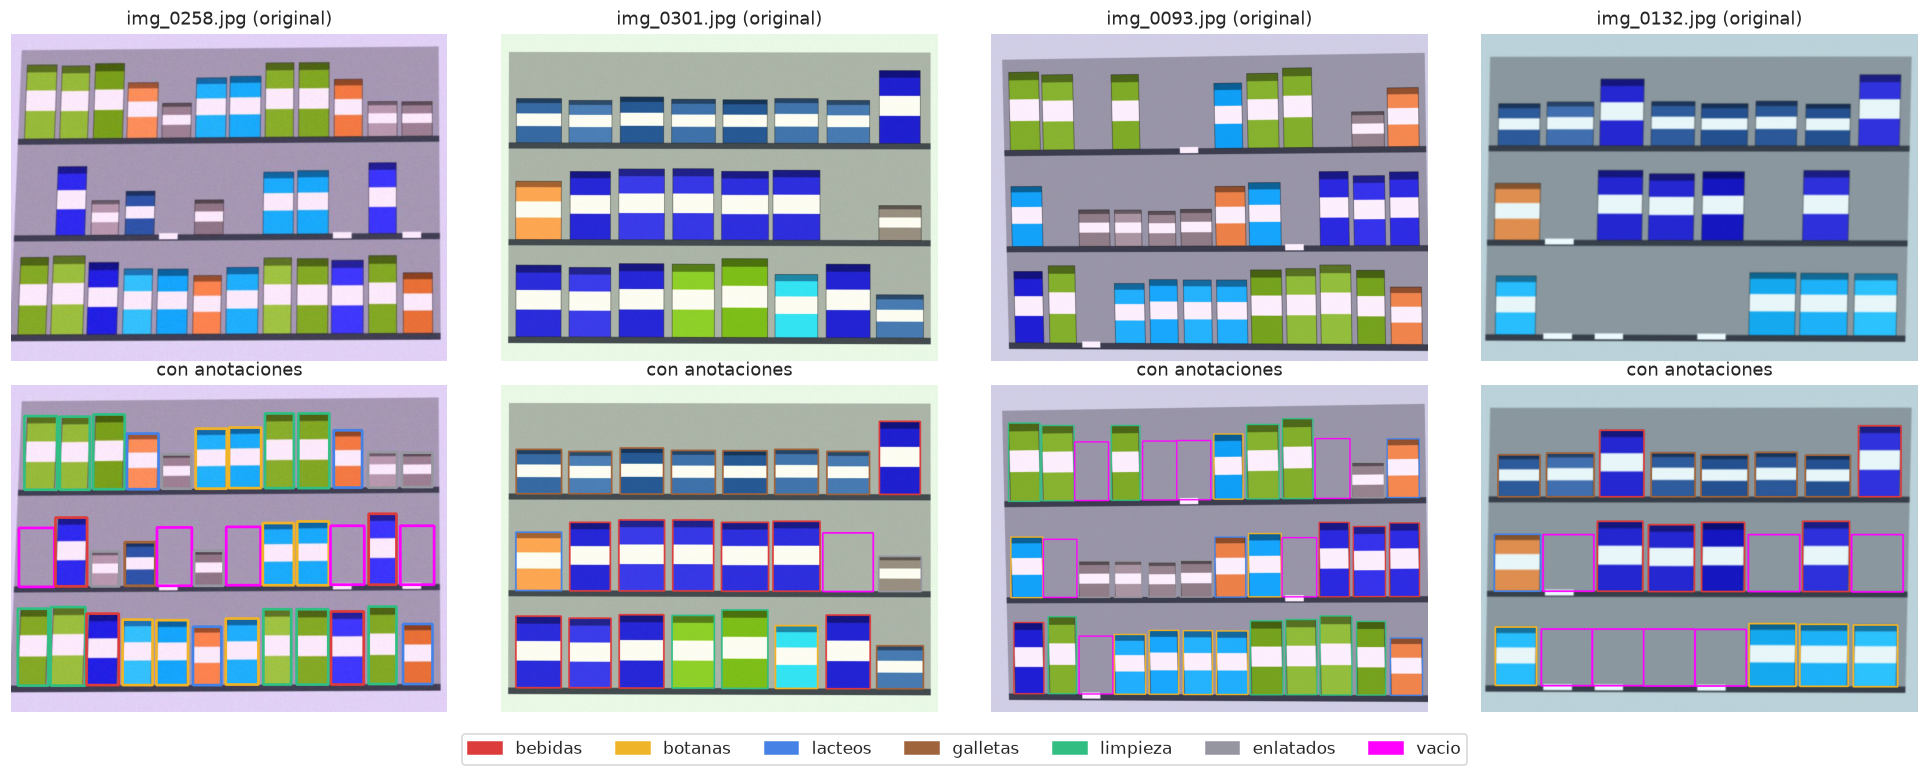

In [4]:
COLORS = {'bebidas':(220,60,60),'botanas':(240,180,40),'lacteos':(70,130,230),'galletas':(160,100,60),
          'limpieza':(50,190,130),'enlatados':(150,150,160),'vacio':(255,0,255)}
def draw_boxes(fn, thick=3):
    im = cv2.imread(os.path.join(IMG_DIR,fn)); h,w = im.shape[:2]
    for _,b in boxes[boxes.image==fn].iterrows():
        p0 = (int(b.xmin*w),int(b.ymin*h)); p1 = (int(b.xmax*w),int(b.ymax*h))
        cv2.rectangle(im,p0,p1,COLORS[b.cls][::-1],thick)
    return im[:,:,::-1]

sample = images_meta.sample(4, random_state=1).image.tolist()
fig, ax = plt.subplots(2,4, figsize=(18,7))
for i,fn in enumerate(sample):
    ax[0,i].imshow(Image.open(os.path.join(IMG_DIR,fn))); ax[0,i].set_title(fn+' (original)'); ax[0,i].axis('off')
    ax[1,i].imshow(draw_boxes(fn)); ax[1,i].set_title('con anotaciones'); ax[1,i].axis('off')
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=np.array(v)/255,label=k) for k,v in COLORS.items()], loc='lower center', ncol=7)
plt.tight_layout(rect=(0,0.05,1,1)); plt.show()

## 3. Características principales (resolución, formato, procedencia)

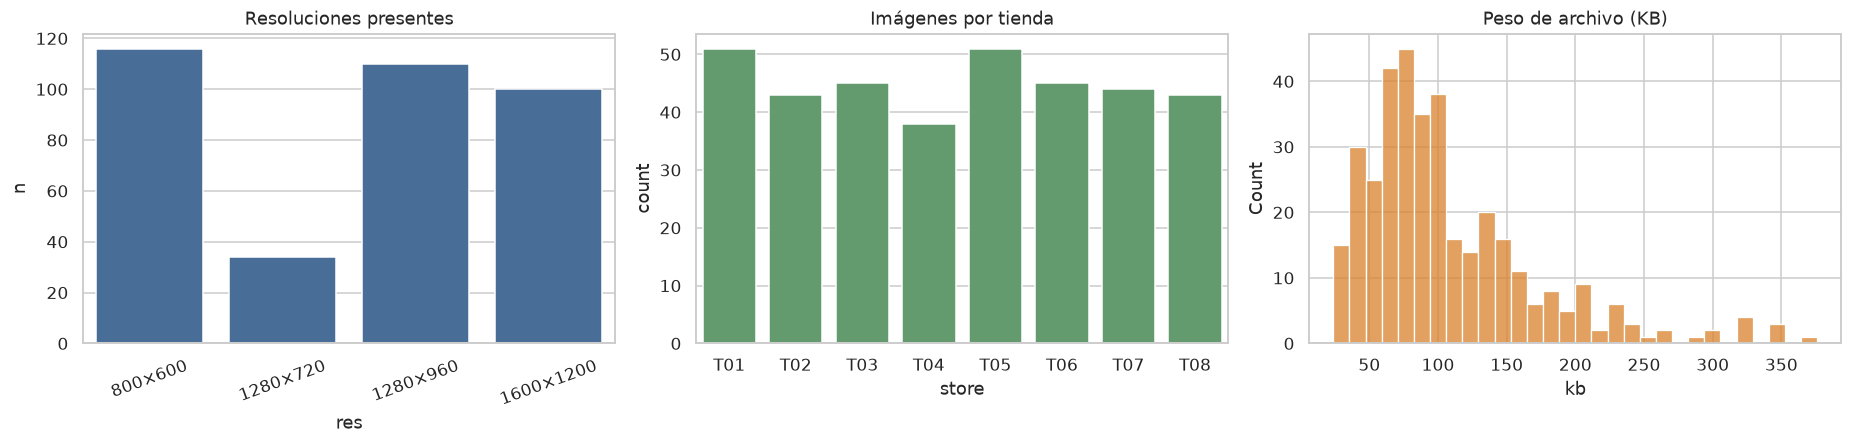

                 Métrica Valor
                Imágenes   360
     Anotaciones (cajas) 12570
Cajas por imagen (media)  34.9
                 Tiendas     8
       Muebles distintos    16
            Dispositivos     4
  Resoluciones distintas     4
   Megapíxeles (mediana)  1.23
       Peso mediano (KB)  89.0
                 Formato  JPEG


In [5]:
rows = []
for fn in images_meta.image:
    with Image.open(os.path.join(IMG_DIR,fn)) as im:
        rows.append((im.width, im.height, im.format, os.path.getsize(os.path.join(IMG_DIR,fn))/1024))
dfres = pd.DataFrame(rows, columns=['w','h','fmt','kb'])
images_meta[['w','h','fmt','kb']] = dfres.values
images_meta['mp'] = images_meta.w*images_meta.h/1e6
images_meta['aspect'] = images_meta.w/images_meta.h

fig, ax = plt.subplots(1,3, figsize=(17,4.2))
res_counts = images_meta.groupby(['w','h']).size().reset_index(name='n')
res_counts['res'] = res_counts.w.astype(str)+'×'+res_counts.h.astype(str)
sns.barplot(data=res_counts, x='res', y='n', ax=ax[0], color='#3b6ea5'); ax[0].set_title('Resoluciones presentes'); ax[0].tick_params(axis='x', rotation=20)
sns.countplot(data=images_meta, x='store', ax=ax[1], color='#5aa469', order=sorted(images_meta.store.unique())); ax[1].set_title('Imágenes por tienda')
sns.histplot(images_meta.kb, bins=30, ax=ax[2], color='#d9822b'); ax[2].set_title('Peso de archivo (KB)')
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
 'Métrica':['Imágenes','Anotaciones (cajas)','Cajas por imagen (media)','Tiendas','Muebles distintos','Dispositivos','Resoluciones distintas','Megapíxeles (mediana)','Peso mediano (KB)','Formato'],
 'Valor':[len(images_meta),len(boxes),round(len(boxes)/len(images_meta),1),images_meta.store.nunique(),
          images_meta.groupby(['store','mueble']).ngroups,images_meta.device.nunique(),len(res_counts),
          round(images_meta.mp.median(),2),round(images_meta.kb.median(),0),', '.join(images_meta.fmt.unique())]})
print(summary.to_string(index=False))

## 4. Clases y espacios vacíos
En el problema de resurtido lo que más interesa es la clase **`vacio`** (posición faltante). Se revisa su proporción y el desbalance entre clases.

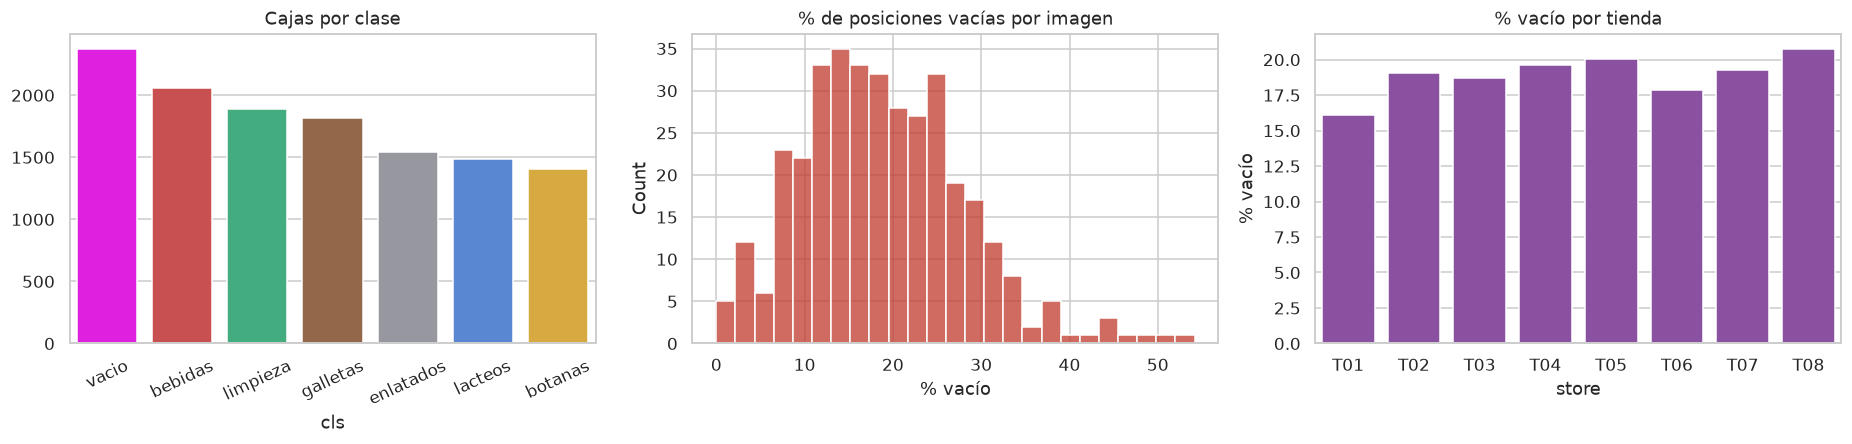

cls
vacio        2376
bebidas      2058
limpieza     1887
galletas     1814
enlatados    1540
lacteos      1488
botanas      1407

Proporción global de vacíos: 18.9%
Desbalance (clase mayor / clase menor): 1.69x
Imágenes SIN ningún vacío: 5 de 360 (1.4%)


In [6]:
cls_counts = boxes.cls.value_counts()
per_img = boxes.groupby('image').agg(n=('cls','size'), n_vacio=('cls',lambda s:(s=='vacio').sum()))
per_img['pct_vacio'] = per_img.n_vacio/per_img.n
fig, ax = plt.subplots(1,3, figsize=(17,4.2))
sns.barplot(x=cls_counts.index, y=cls_counts.values, ax=ax[0], palette=[np.array(COLORS[c])/255 for c in cls_counts.index])
ax[0].set_title('Cajas por clase'); ax[0].tick_params(axis='x', rotation=25)
sns.histplot(per_img.pct_vacio*100, bins=25, ax=ax[1], color='#c0392b'); ax[1].set_title('% de posiciones vacías por imagen'); ax[1].set_xlabel('% vacío')
bd = boxes.merge(images_meta[['image','store']], on='image')
tv = bd.groupby('store').apply(lambda d:(d.cls=='vacio').mean()*100)
sns.barplot(x=tv.index, y=tv.values, ax=ax[2], color='#8e44ad'); ax[2].set_title('% vacío por tienda'); ax[2].set_ylabel('% vacío')
plt.tight_layout(); plt.show()
ratio = cls_counts.max()/cls_counts.min()
print(cls_counts.to_string())
print(f'\nProporción global de vacíos: {(boxes.cls=="vacio").mean()*100:.1f}%')
print(f'Desbalance (clase mayor / clase menor): {ratio:.2f}x')
print(f'Imágenes SIN ningún vacío: {(per_img.n_vacio==0).sum()} de {len(per_img)} ({(per_img.n_vacio==0).mean()*100:.1f}%)')

## 5. Densidad de objetos y tamaño de las cajas
Anaqueles densos con objetos pequeños son el principal reto de detección (Goldman et al., 2019). Se mide cuántos objetos hay por imagen y qué fracción de la imagen ocupa cada caja, y qué tamaño en píxeles tendría tras reescalar a la entrada típica de un detector (640 px).

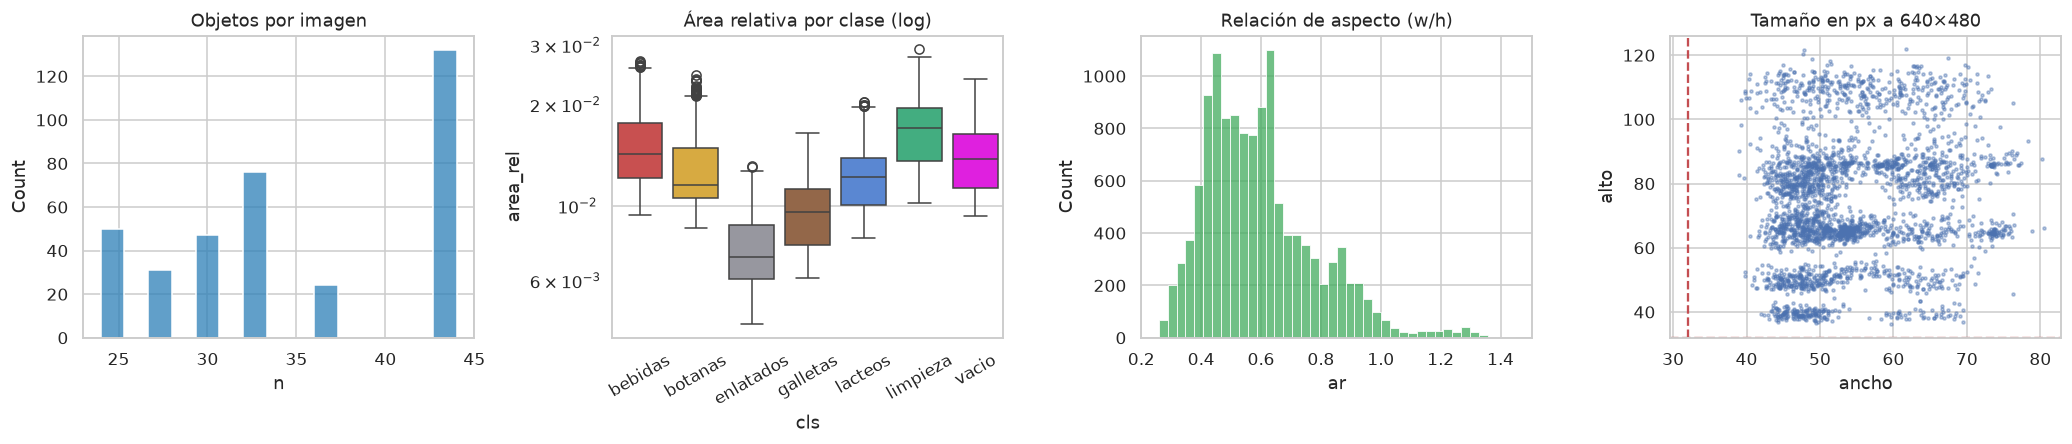

Objetos por imagen: media 34.9, mediana 32, máx 44
Cajas "pequeñas" (<32 px en alguna dimensión a 640×480): 0.0%

Mediana de tamaño a 640×480 (px) por clase:
                w640        h640
cls                             
bebidas    50.700001   80.000000
botanas    48.900002   70.900002
enlatados  49.400002   40.599998
galletas   50.099998   51.099998
lacteos    50.000000   65.699997
limpieza   51.099998  104.099998
vacio      55.400002   66.199997


In [7]:
boxes['w_rel'] = boxes.xmax-boxes.xmin; boxes['h_rel'] = boxes.ymax-boxes.ymin
boxes['area_rel'] = boxes.w_rel*boxes.h_rel; boxes['ar'] = boxes.w_rel/boxes.h_rel
boxes['cx'] = (boxes.xmin+boxes.xmax)/2; boxes['cy'] = (boxes.ymin+boxes.ymax)/2
INPUT = 640
boxes['w640'] = boxes.w_rel*INPUT; boxes['h640'] = boxes.h_rel*INPUT*0.75   # entrada 640x480 (4:3)
boxes['small'] = (boxes.w640<32)|(boxes.h640<32)
fig, ax = plt.subplots(1,4, figsize=(19,4.2))
sns.histplot(per_img.n, bins=15, ax=ax[0], color='#2c7fb8'); ax[0].set_title('Objetos por imagen')
sns.boxplot(data=boxes, x='cls', y='area_rel', ax=ax[1], palette=[np.array(COLORS[c])/255 for c in sorted(boxes.cls.unique())], order=sorted(boxes.cls.unique()))
ax[1].set_yscale('log'); ax[1].set_title('Área relativa por clase (log)'); ax[1].tick_params(axis='x', rotation=30)
sns.histplot(boxes.ar.clip(0,3), bins=40, ax=ax[2], color='#41ab5d'); ax[2].set_title('Relación de aspecto (w/h)')
ax[3].scatter(boxes.w640.sample(3000,random_state=0), boxes.h640.sample(3000,random_state=0), s=4, alpha=.4)
ax[3].axvline(32,color='r',ls='--'); ax[3].axhline(32,color='r',ls='--'); ax[3].set_title('Tamaño en px a 640×480'); ax[3].set_xlabel('ancho'); ax[3].set_ylabel('alto')
plt.tight_layout(); plt.show()
print(f'Objetos por imagen: media {per_img.n.mean():.1f}, mediana {per_img.n.median():.0f}, máx {per_img.n.max()}')
print(f'Cajas "pequeñas" (<32 px en alguna dimensión a 640×480): {boxes.small.mean()*100:.1f}%')
print('\nMediana de tamaño a 640×480 (px) por clase:')
print(boxes.groupby('cls')[['w640','h640']].median().round(1).to_string())

## 6. Distribución espacial
¿Dónde aparecen los vacíos dentro de la imagen? Útil para decidir aumentos de datos (recortes, volteos) y para saber si existe sesgo de posición.

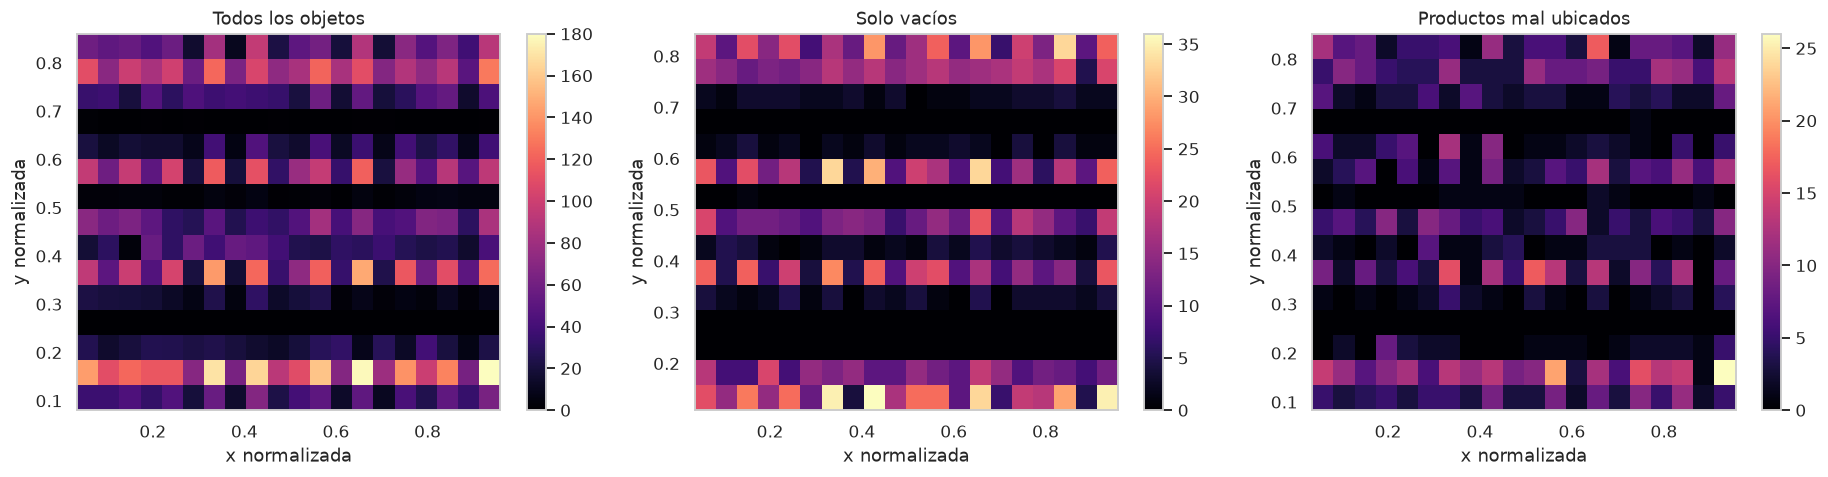

state  correcto  faltante  mal_ubicado
shelf                                 
0          70.7      19.7          9.6
1          71.7      19.0          9.3
2          71.3      18.5         10.2
3          72.5      17.9          9.5


In [8]:
fig, ax = plt.subplots(1,3, figsize=(17,4.5))
for a,(name,d) in zip(ax,[('Todos los objetos',boxes),('Solo vacíos',boxes[boxes.cls=='vacio']),('Productos mal ubicados',boxes[boxes.state=='mal_ubicado'])]):
    h = a.hist2d(d.cx, 1-d.cy, bins=[20,15], cmap='magma'); a.set_title(name); a.set_xlabel('x normalizada'); a.set_ylabel('y normalizada'); plt.colorbar(h[3], ax=a)
plt.tight_layout(); plt.show()
shelf_state = boxes.groupby(['shelf','state']).size().unstack(fill_value=0)
print((shelf_state.div(shelf_state.sum(1),axis=0)*100).round(1).to_string())

## 7. Calidad de imagen
Para cada imagen se calculan, a partir del archivo en disco: **brillo** (media de V en HSV), **contraste** (desviación estándar de grises), **nitidez** (varianza del Laplaciano, valores bajos = desenfoque) y **ruido** (desviación del residuo entre la imagen y su versión suavizada).

In [9]:
def img_metrics(fn):
    im = cv2.imread(os.path.join(IMG_DIR,fn)); g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    g640 = cv2.resize(g,(640,480),interpolation=cv2.INTER_AREA)   # normaliza resolución para comparar nitidez
    hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    lap = cv2.Laplacian(g640, cv2.CV_64F).var()
    res = g640.astype(np.float32)-cv2.GaussianBlur(g640,(0,0),1.2).astype(np.float32)
    noise = float(np.median(np.abs(res))/0.6745)
    clipped = float(((g<=5)|(g>=250)).mean()*100)
    return dict(brillo=hsv[...,2].mean(), contraste=g.std(), nitidez=lap, ruido=noise, saturacion=hsv[...,1].mean(), pix_saturados_pct=clipped)
qm = pd.DataFrame([img_metrics(f) for f in images_meta.image])
images_meta = pd.concat([images_meta.drop(columns=[c for c in qm.columns if c in images_meta.columns]), qm], axis=1)
print(qm.describe().round(2).T[['mean','std','min','50%','max']].to_string())

                     mean     std    min     50%      max
brillo             160.09   35.31  73.95  164.60   226.26
contraste           44.27    9.57  20.42   46.32    66.11
nitidez            213.48  192.09   7.17  148.63  1032.09
ruido                1.19    0.85   0.00    1.48     2.97
saturacion          66.42    9.78  37.63   65.82    97.40
pix_saturados_pct    1.89    4.82   0.00    0.00    26.84


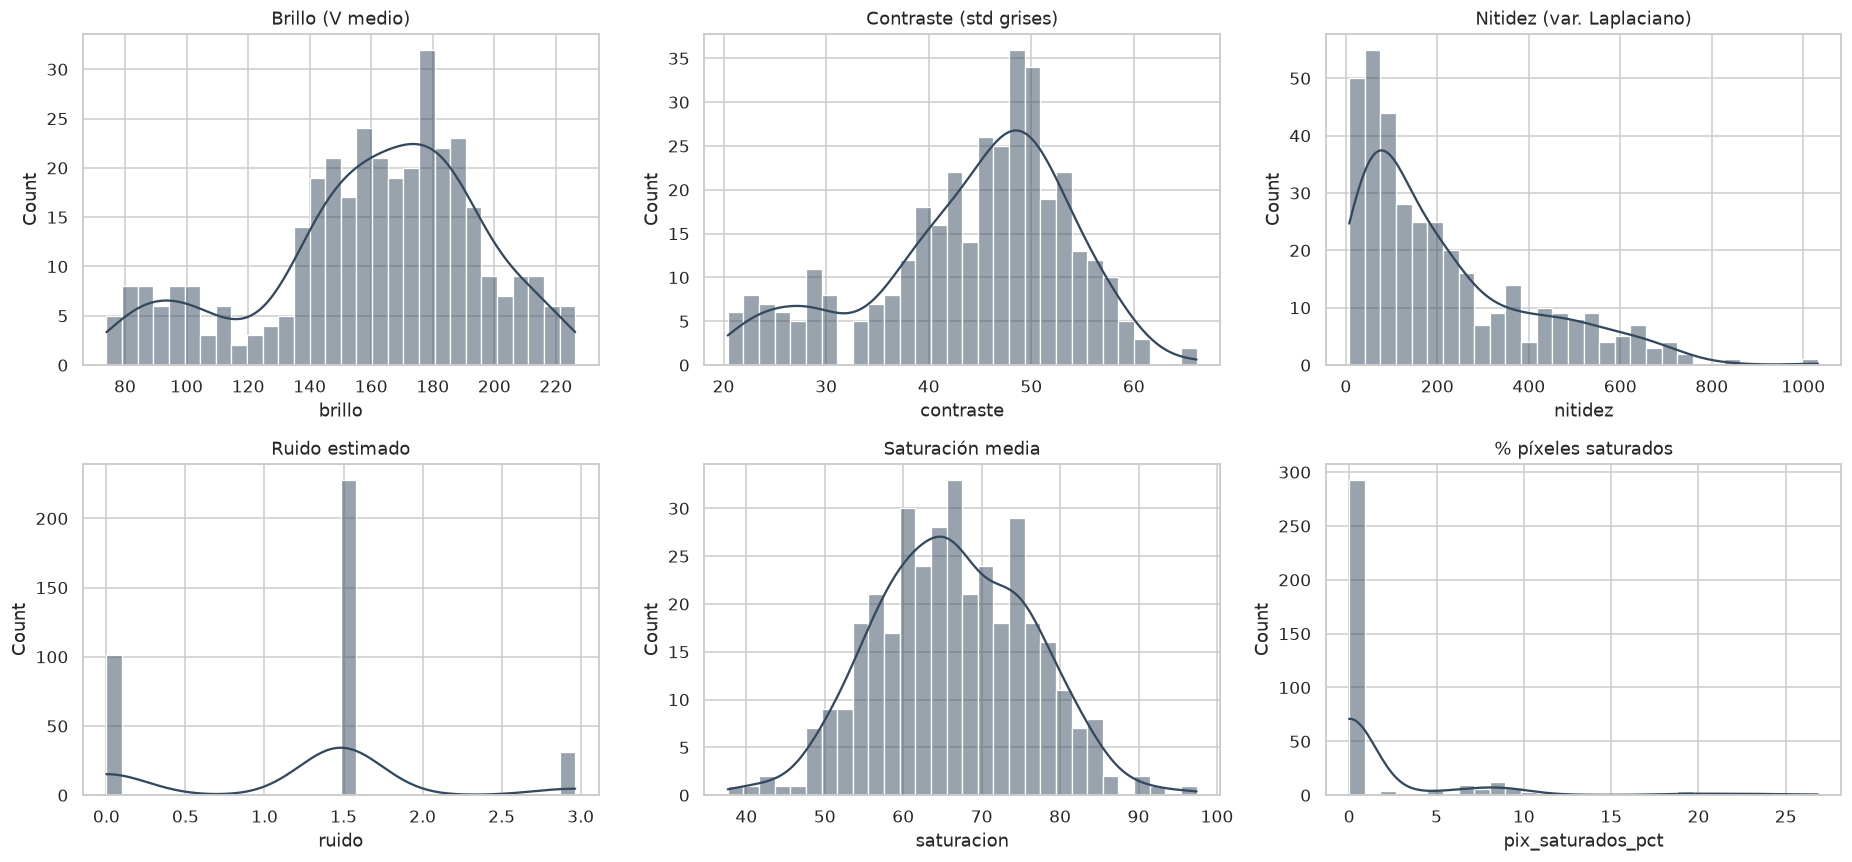

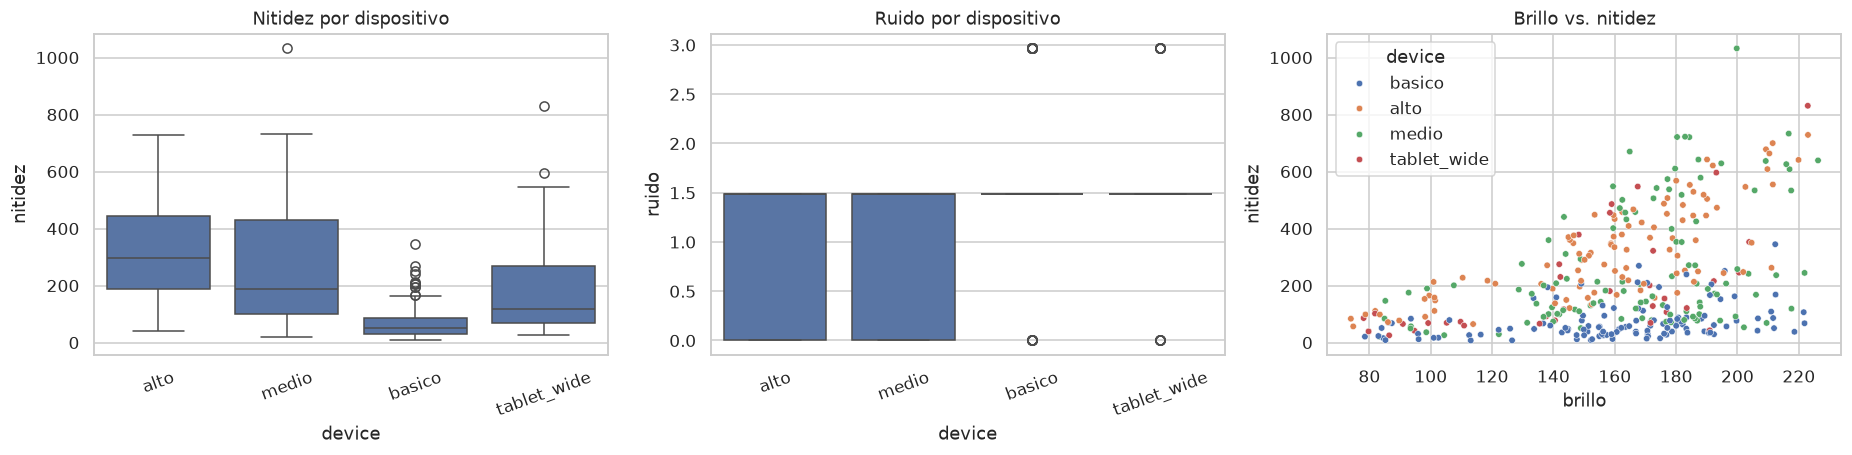

In [10]:
fig, ax = plt.subplots(2,3, figsize=(17,8))
for a,(c,t) in zip(ax.ravel(),[('brillo','Brillo (V medio)'),('contraste','Contraste (std grises)'),('nitidez','Nitidez (var. Laplaciano)'),
                               ('ruido','Ruido estimado'),('saturacion','Saturación media'),('pix_saturados_pct','% píxeles saturados')]):
    sns.histplot(images_meta[c], bins=30, ax=a, color='#34495e', kde=True); a.set_title(t)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1,3, figsize=(17,4.3))
order = list(DEVICES)
sns.boxplot(data=images_meta, x='device', y='nitidez', order=order, ax=ax[0]); ax[0].set_title('Nitidez por dispositivo'); ax[0].tick_params(axis='x', rotation=20)
sns.boxplot(data=images_meta, x='device', y='ruido', order=order, ax=ax[1]); ax[1].set_title('Ruido por dispositivo'); ax[1].tick_params(axis='x', rotation=20)
sns.scatterplot(data=images_meta, x='brillo', y='nitidez', hue='device', ax=ax[2], s=18); ax[2].set_title('Brillo vs. nitidez')
plt.tight_layout(); plt.show()

% de imágenes con cada problema de calidad:
flag_oscura       4.2
flag_sobreexp    18.6
flag_borrosa     10.0
flag_ruidosa      8.6
flag_any         37.5

Umbral de nitidez (p10): 34.7

% con bandera por dispositivo:
             flag_oscura  flag_sobreexp  flag_borrosa  flag_ruidosa  flag_any
device                                                                       
alto                 6.0           16.0           0.0           0.0      22.0
basico               3.4           19.0          27.6          19.8      59.5
medio                1.8           20.9           2.7           0.0      24.5
tablet_wide          8.8           17.6           2.9          23.5      50.0


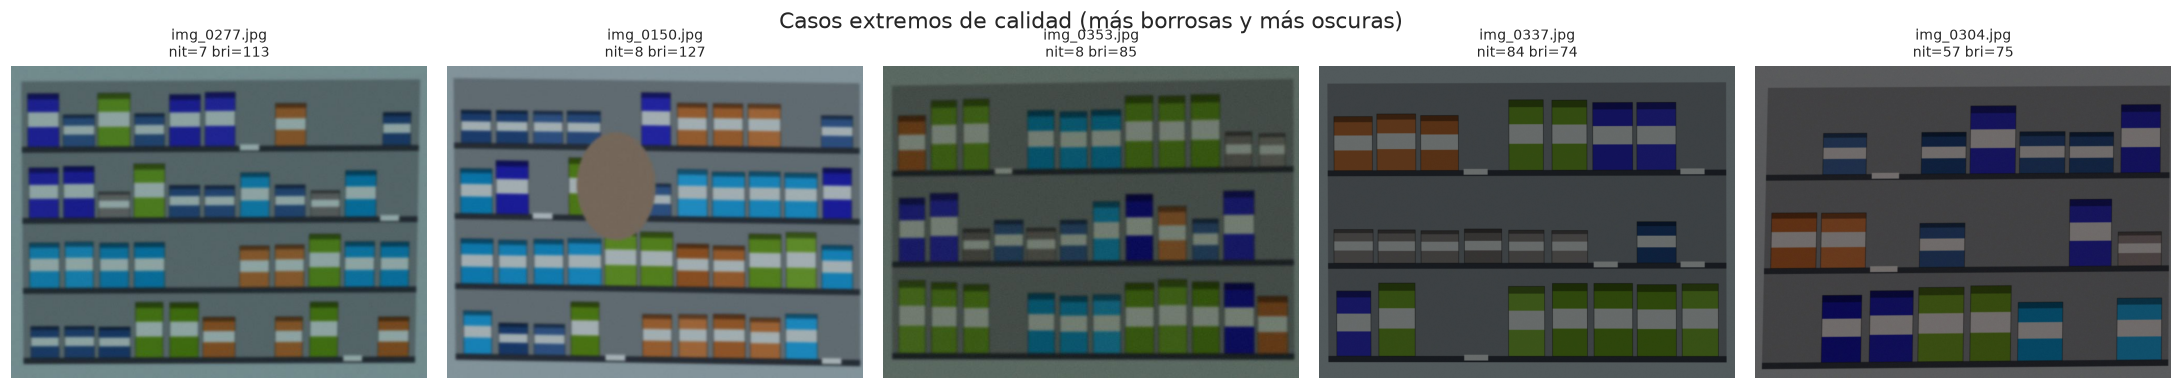

In [11]:
# Umbrales de "mala calidad" (percentiles / reglas simples; deben calibrarse con revisión visual en datos reales)
thr_blur = images_meta.nitidez.quantile(0.10)
images_meta['flag_oscura'] = images_meta.brillo < 85
images_meta['flag_sobreexp'] = images_meta.brillo > 190
images_meta['flag_borrosa'] = images_meta.nitidez < thr_blur
images_meta['flag_ruidosa'] = images_meta.ruido > images_meta.ruido.quantile(0.90)
flags = ['flag_oscura','flag_sobreexp','flag_borrosa','flag_ruidosa']
images_meta['flag_any'] = images_meta[flags].any(axis=1)
qs = images_meta[flags+['flag_any']].mean().mul(100).round(1)
print('% de imágenes con cada problema de calidad:'); print(qs.to_string())
print(f'\nUmbral de nitidez (p10): {thr_blur:.1f}')
print('\n% con bandera por dispositivo:'); print((images_meta.groupby('device')[flags+['flag_any']].mean()*100).round(1).to_string())
bad = images_meta.sort_values('nitidez').head(3).image.tolist() + images_meta.sort_values('brillo').head(2).image.tolist()
fig, ax = plt.subplots(1,5, figsize=(20,3.6))
for a,fn in zip(ax,bad):
    r = images_meta[images_meta.image==fn].iloc[0]; a.imshow(Image.open(os.path.join(IMG_DIR,fn))); a.axis('off')
    a.set_title(f'{fn}\nnit={r.nitidez:.0f} bri={r.brillo:.0f}', fontsize=9)
plt.suptitle('Casos extremos de calidad (más borrosas y más oscuras)'); plt.tight_layout(); plt.show()

## 8. Anatomía de una imagen: histogramas, bordes y canales
Se descompone una imagen representativa para entender qué información visual aprovecha un detector: distribución de intensidades por canal, mapa de nitidez local (Laplaciano) y bordes (Canny).

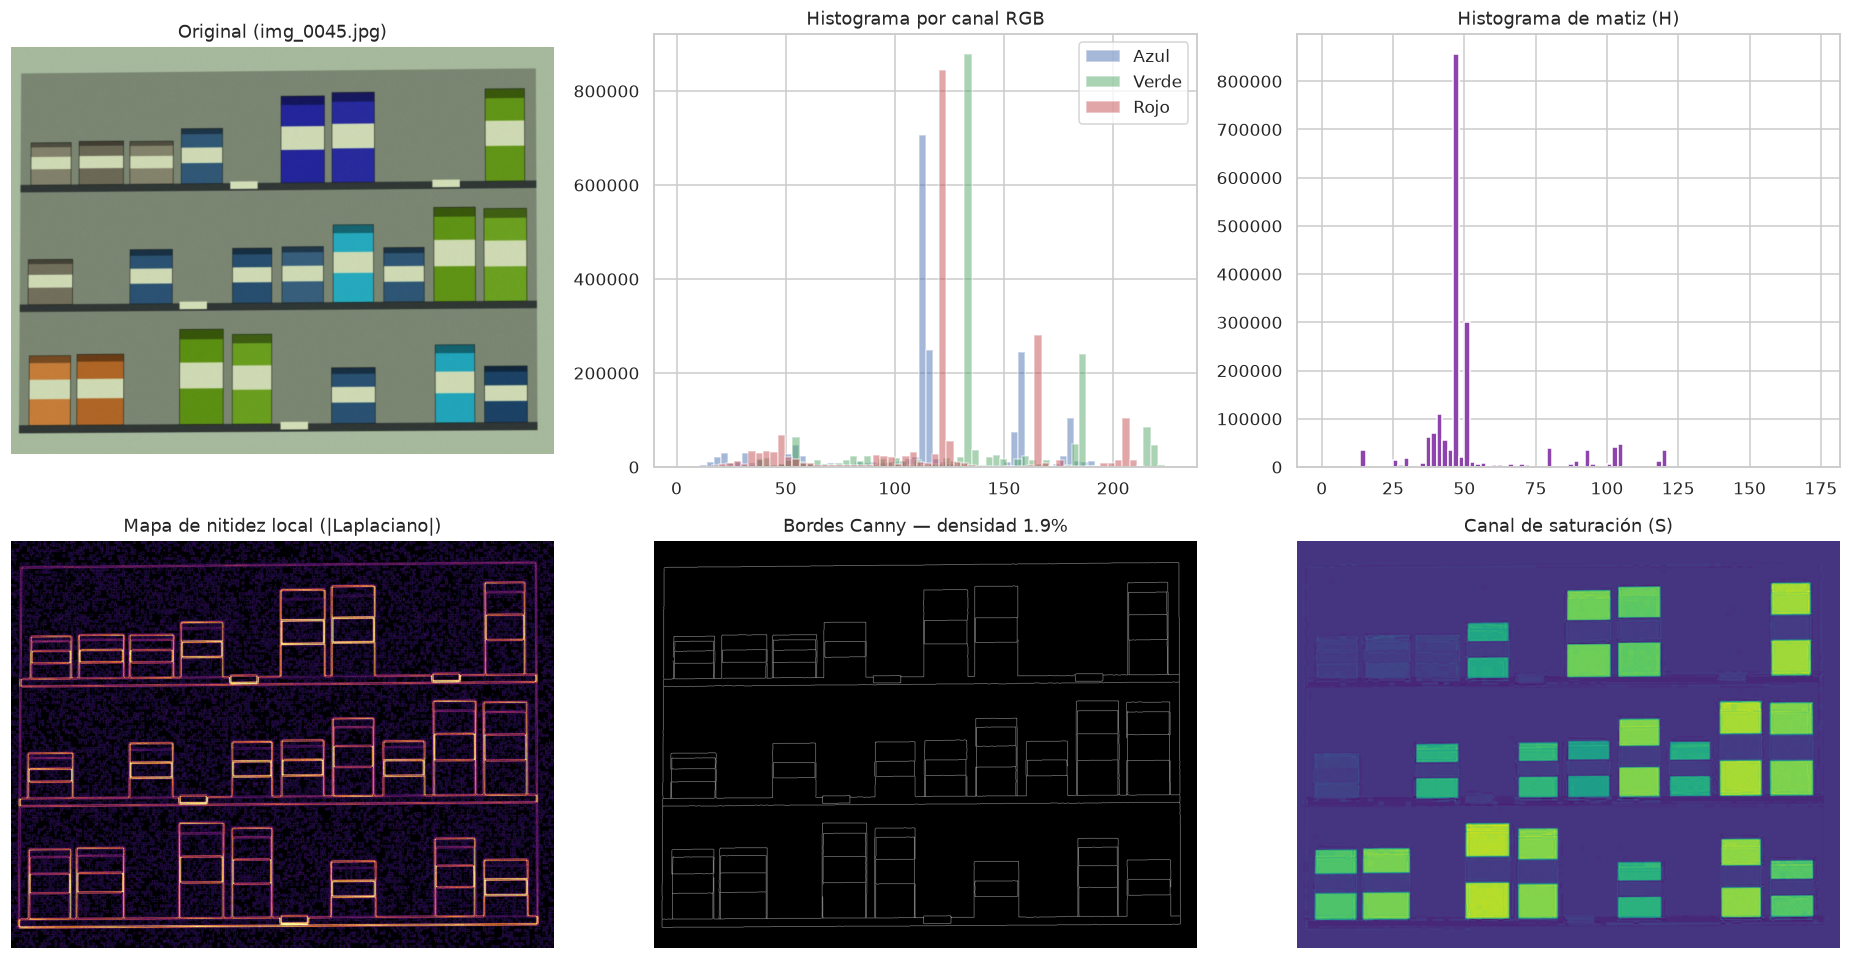

In [12]:
fn = images_meta.sort_values('nitidez').iloc[len(images_meta)//2].image
im = cv2.imread(os.path.join(IMG_DIR,fn)); g = cv2.cvtColor(im,cv2.COLOR_BGR2GRAY); hsv = cv2.cvtColor(im,cv2.COLOR_BGR2HSV)
lap = np.abs(cv2.Laplacian(cv2.GaussianBlur(g,(0,0),1),cv2.CV_64F)); edges = cv2.Canny(g,60,140)
fig, ax = plt.subplots(2,3, figsize=(17,9))
ax[0,0].imshow(im[:,:,::-1]); ax[0,0].set_title(f'Original ({fn})')
for i,(c,n) in enumerate(zip('bgr',['Azul','Verde','Rojo'])): ax[0,1].hist(im[...,i].ravel(), bins=64, color=c, alpha=.5, label=n)
ax[0,1].legend(); ax[0,1].set_title('Histograma por canal RGB')
ax[0,2].hist(hsv[...,0].ravel(), bins=90, color='#8e44ad'); ax[0,2].set_title('Histograma de matiz (H)')
ax[1,0].imshow(lap, cmap='inferno', vmax=np.percentile(lap,99)); ax[1,0].set_title('Mapa de nitidez local (|Laplaciano|)')
ax[1,1].imshow(edges, cmap='gray'); ax[1,1].set_title(f'Bordes Canny — densidad {edges.mean()/255*100:.1f}%')
ax[1,2].imshow(hsv[...,1], cmap='viridis'); ax[1,2].set_title('Canal de saturación (S)')
for a in [ax[0,0],ax[1,0],ax[1,1],ax[1,2]]: a.axis('off')
plt.tight_layout(); plt.show()

## 9. Color por clase y separabilidad
Se extraen los recortes de cada caja y se calcula su perfil de color medio (HSV). Con PCA sobre histogramas de color se estima cuánto se separan las clases *solo por color*. En datos reales (empaques variados) la separabilidad será menor; aquí sirve para ilustrar el análisis.

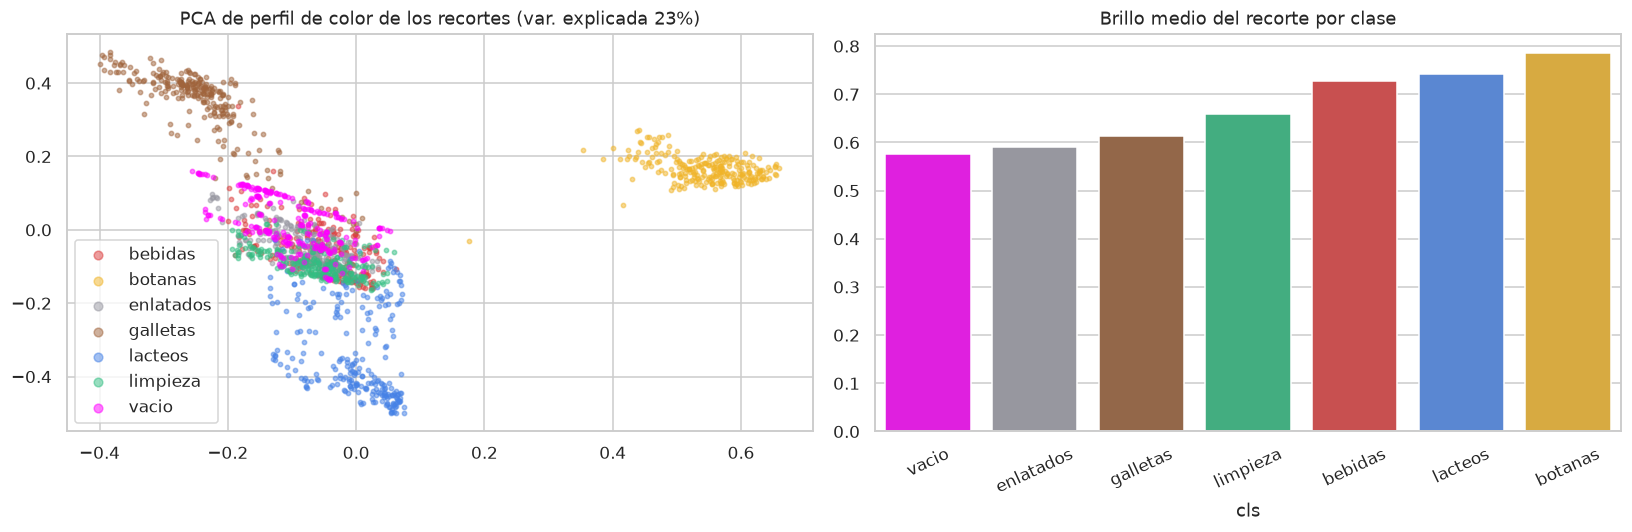

Exactitud (CV 5 pliegues) de un clasificador trivial solo con color: 0.97  (referencia de azar: 0.14)


In [13]:
from sklearn.decomposition import PCA
sub = pd.concat([d.sample(min(len(d),250), random_state=0) for _,d in boxes.groupby('cls')])
feats, labels = [], []
cache = {}
for _,b in sub.iterrows():
    if b.image not in cache: cache[b.image] = cv2.imread(os.path.join(IMG_DIR,b.image))
    im = cache[b.image]; h,w = im.shape[:2]
    crop = im[int(b.ymin*h):int(b.ymax*h), int(b.xmin*w):int(b.xmax*w)]
    if crop.size==0 or min(crop.shape[:2])<4: continue
    hs = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hs],[0,1],None,[12,4],[0,180,0,256]).ravel(); hist /= hist.sum()+1e-9
    feats.append(np.r_[hist, hs[...,2].mean()/255]); labels.append(b.cls)
X = np.array(feats); pca = PCA(2).fit(X); Z = pca.transform(X)
fig, ax = plt.subplots(1,2, figsize=(15,5))
for c in sorted(set(labels)):
    m = np.array(labels)==c; ax[0].scatter(Z[m,0],Z[m,1],s=8,alpha=.5,label=c,color=np.array(COLORS[c])/255)
ax[0].legend(markerscale=2); ax[0].set_title(f'PCA de perfil de color de los recortes (var. explicada {pca.explained_variance_ratio_.sum()*100:.0f}%)')
mean_hsv = pd.DataFrame(X[:,-1], columns=['V']).assign(cls=labels).groupby('cls').V.mean().sort_values()
sns.barplot(x=mean_hsv.index, y=mean_hsv.values, ax=ax[1], palette=[np.array(COLORS[c])/255 for c in mean_hsv.index]); ax[1].set_title('Brillo medio del recorte por clase'); ax[1].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
sc = cross_val_score(RandomForestClassifier(100, random_state=0), X, labels, cv=5).mean()
print(f'Exactitud (CV 5 pliegues) de un clasificador trivial solo con color: {sc:.2f}  (referencia de azar: {1/len(set(labels)):.2f})')

## 10. Duplicados y data leakage
En capturas de anaquel es común fotografiar el mismo mueble varias veces. Si esas imágenes caen en particiones distintas (entrenamiento / prueba) se infla artificialmente el desempeño. Se detectan casi-duplicados con un *average hash* de 64 bits (distancia de Hamming).

Pares candidatos a duplicado (dist ≤ 40/256): 14
Pares reales de la misma escena (verdad terreno sintética): 30
Precisión del detector: 0.93 | Recall: 0.43


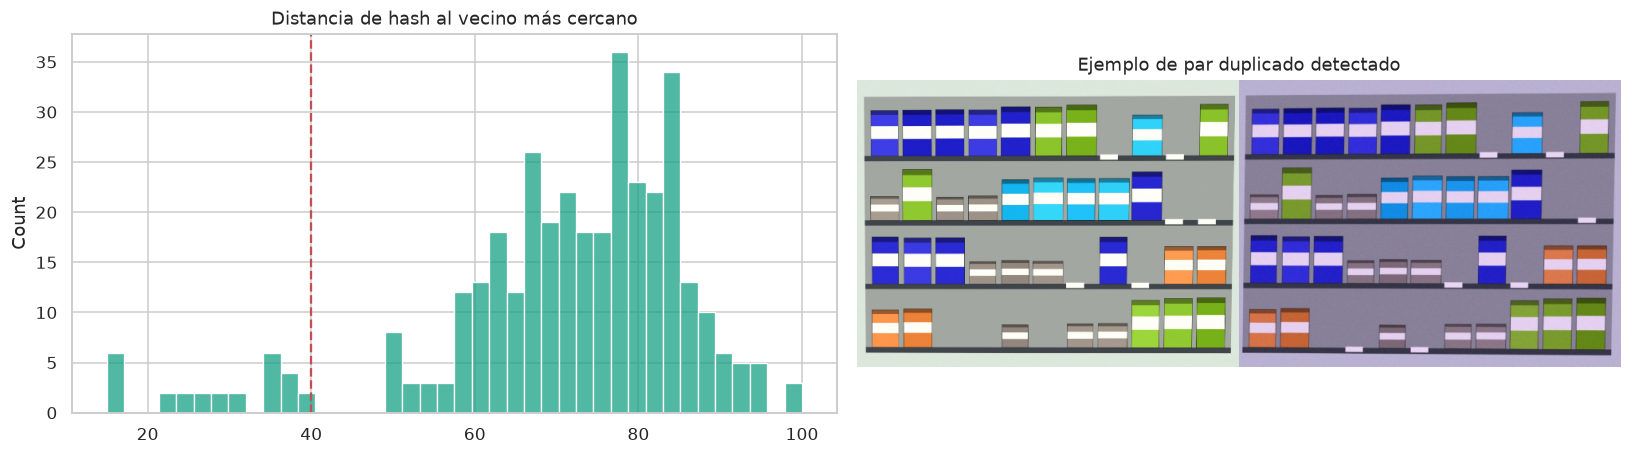

Imágenes involucradas en algún par duplicado: 28 (7.8%)


In [14]:
def ahash(fn, s=8):
    g = cv2.cvtColor(cv2.imread(os.path.join(IMG_DIR,fn)), cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g,(s,s),interpolation=cv2.INTER_AREA).astype(np.float32)
    return (g>g.mean()).ravel()
def dhash(fn, s=16):
    g = cv2.cvtColor(cv2.imread(os.path.join(IMG_DIR,fn)), cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g,(s+1,s),interpolation=cv2.INTER_AREA).astype(np.float32)
    return (g[:,1:]>g[:,:-1]).ravel()
H = np.array([dhash(f) for f in images_meta.image]); n = len(H)
D = (H[:,None,:]!=H[None,:,:]).sum(-1); np.fill_diagonal(D, 999)
TH = 40   # umbral sobre 256 bits (calibrado visualmente)
pairs = np.argwhere(np.triu(D<=TH)); 
same_scene = images_meta.scene_id.values
tp = sum(same_scene[i]==same_scene[j] for i,j in pairs); 
true_pairs = sum(1 for i in range(n) for j in range(i+1,n) if same_scene[i]==same_scene[j])
print(f'Pares candidatos a duplicado (dist ≤ {TH}/256): {len(pairs)}')
print(f'Pares reales de la misma escena (verdad terreno sintética): {true_pairs}')
print(f'Precisión del detector: {tp/max(len(pairs),1):.2f} | Recall: {tp/max(true_pairs,1):.2f}')
dmin = D.min(1)
fig, ax = plt.subplots(1,2, figsize=(15,4.3))
sns.histplot(dmin, bins=40, ax=ax[0], color='#16a085'); ax[0].axvline(TH,color='r',ls='--'); ax[0].set_title('Distancia de hash al vecino más cercano')
if len(pairs):
    i,j = pairs[0]; ax[1].imshow(np.hstack([cv2.resize(cv2.imread(os.path.join(IMG_DIR,images_meta.image[k]))[:,:,::-1],(480,360)) for k in (i,j)])); ax[1].axis('off'); ax[1].set_title('Ejemplo de par duplicado detectado')
plt.tight_layout(); plt.show()
dup_imgs = set(pairs.ravel().tolist()); print(f'Imágenes involucradas en algún par duplicado: {len(dup_imgs)} ({len(dup_imgs)/n*100:.1f}%)')

## 11. Planograma y estado por posición
La variable de negocio es el **estado por posición** (correcto / faltante / mal ubicado). Se analiza su distribución, la diferencia entre lo esperado y lo observado y el efecto de la oclusión.

state
correcto       71.4
faltante       18.9
mal_ubicado     9.7


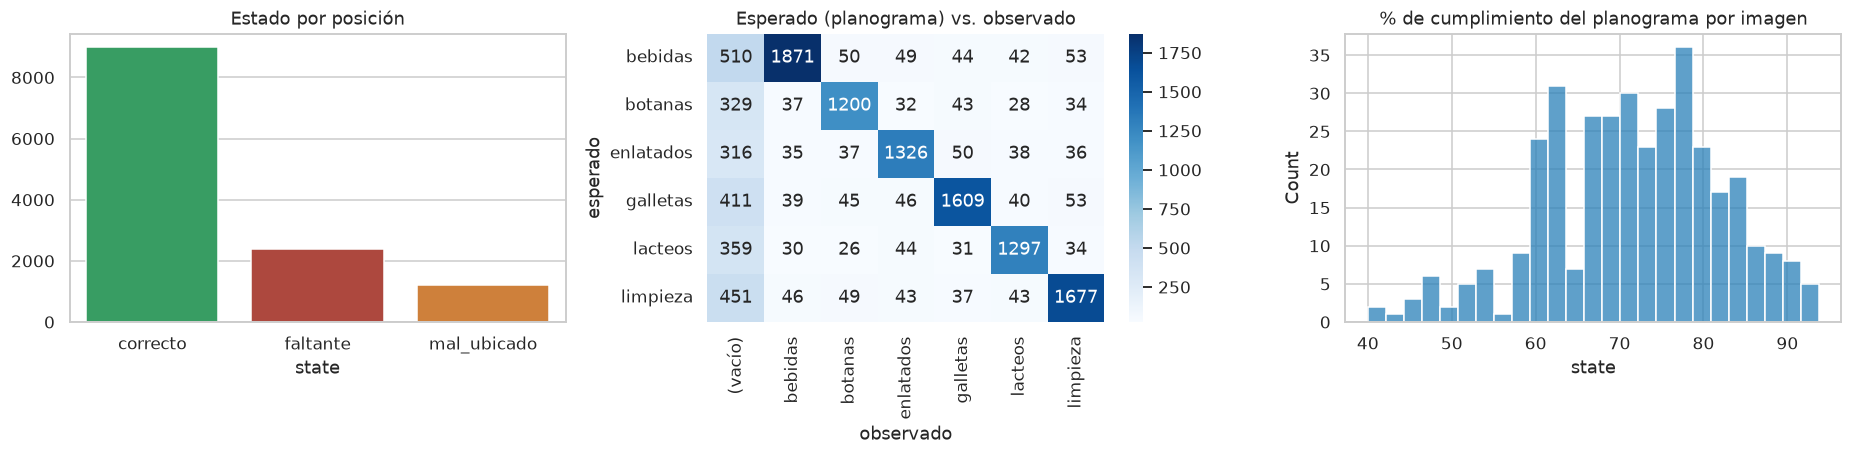

Cumplimiento medio del planograma: 71.5% (desv. est. 10.4)
Cajas con oclusión > 30%: 1.05%  | imágenes con oclusor: 10.6%


In [15]:
slots = boxes.drop_duplicates(['image','shelf','slot']).copy()
st = slots.state.value_counts(); print((st/st.sum()*100).round(1).to_string())
fig, ax = plt.subplots(1,3, figsize=(17,4.3))
sns.barplot(x=st.index, y=st.values, ax=ax[0], palette=['#27ae60','#c0392b','#e67e22']); ax[0].set_title('Estado por posición')
conf = pd.crosstab(slots.expected, slots.cls.replace({'vacio':'(vacío)'}))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', ax=ax[1]); ax[1].set_title('Esperado (planograma) vs. observado'); ax[1].set_ylabel('esperado'); ax[1].set_xlabel('observado')
per_img_state = slots.groupby('image').state.apply(lambda s:(s=='correcto').mean()*100)
sns.histplot(per_img_state, bins=25, ax=ax[2], color='#2980b9'); ax[2].set_title('% de cumplimiento del planograma por imagen')
plt.tight_layout(); plt.show()
print(f'Cumplimiento medio del planograma: {per_img_state.mean():.1f}% (desv. est. {per_img_state.std():.1f})')
print(f'Cajas con oclusión > 30%: {(boxes.occ>0.3).mean()*100:.2f}%  | imágenes con oclusor: {images_meta.has_occluder.mean()*100:.1f}%')

## 12. Factibilidad: ¿qué tan difícil es detectar?
Se resumen en un tablero los indicadores que más pesan en la dificultad (densidad, objetos pequeños, calidad, oclusión, duplicados, desbalance) y se normalizan a un índice 0–1 solo con fines comparativos.

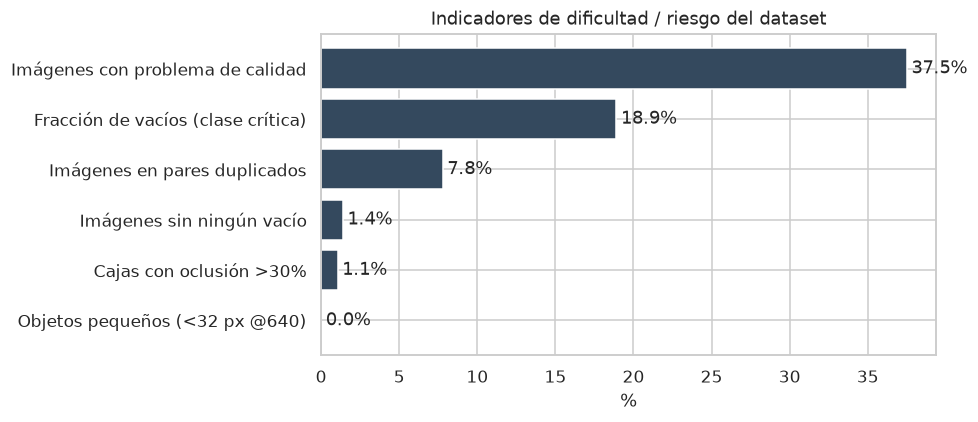

In [16]:
ind = {
 'Objetos pequeños (<32 px @640)': boxes.small.mean(),
 'Imágenes con problema de calidad': images_meta.flag_any.mean(),
 'Cajas con oclusión >30%': (boxes.occ>0.3).mean(),
 'Imágenes en pares duplicados': len(dup_imgs)/n,
 'Imágenes sin ningún vacío': (per_img.n_vacio==0).mean(),
 'Fracción de vacíos (clase crítica)': (boxes.cls=='vacio').mean(),
}
fig, ax = plt.subplots(figsize=(9,4))
s = pd.Series(ind).sort_values()
ax.barh(s.index, s.values*100, color='#34495e'); ax.set_xlabel('%'); ax.set_title('Indicadores de dificultad / riesgo del dataset')
for i,v in enumerate(s.values): ax.text(v*100+0.3,i,f'{v*100:.1f}%',va='center')
plt.tight_layout(); plt.show()